# 第7章 ステップ幅を取り出す ―― 配列の操作を組み合わせる

**この章でできるようになること**
- `np.diff` で傾き |dV/dI| を求め、中点に置ける
- 0 で割ったときの `inf`・`nan` を `np.errstate`・`np.isfinite` で扱える
- 2つの条件をブールマスクで組み合わせ、`np.where`・`np.split` で「連続した塊」に分けられる
- 研究と同じ方法でステップ幅 ΔI を取り出し、A に対する変化（ローブ）を図にできる

**例え：** ステップ幅を測るのは「坂道の**踊り場の長さ**を測る」ことです。①高さ（電圧）がちょうど踊り場の高さに近く、②ほとんど平ら（傾きが小さい）なところに印を付け、③印が**とぎれずに続いている一番長い区間**の長さを測ります。

| 用語 | 意味 | 例え |
|---|---|---|
| ステップ幅 ΔI | 段の上で電圧が一定のまま、電流がどれだけ変えられるか | 踊り場の長さ |
| 中点 | 隣り合う2点のまん中 | 2本の柱のまん中 |
| しきい値（thr） | 「平ら」とみなす傾きの上限。研究では 0.02 | 「水平器の泡がこの範囲なら平ら」 |
| 窓（srange） | 「この電圧の近く」とみなす幅。(−1,1) では ±0.04 | 「踊り場の高さ ±何 cm」 |
| inf / nan | 無限大 / 数でない値（0÷0 など） | 「測れない」の印 |
| 連続した塊 | 番号がとぎれずに続いている部分 | とぎれずに続く印の列 |
| ローブ | A を変えたとき、ステップ幅が山になって増えたり減ったりする、その1つ1つの山 | 波の1つ1つの山 |

> 研究コードとのつながり：`py/load.py` の `extract`（MATLAB の extract_step_width と同じ手順。研究リポジトリの `lab/式と前提.md` 4章）を、この章で1行ずつ作ります。教材の `kyozai/step.py` も同じものです。

In [1]:
# 準備：教材の部品（kyozai/）を import できるようにする。どの章でも最初に1回だけ実行する。
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "kyozai").exists():   # kyozai/ があるフォルダまで上にたどる
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("教材の場所:", ROOT.name)

教材の場所: python-from-my-research


## 7.1 データを読み込む

第6章で作った β = 10 の IV マップを読み込みます（ファイルがなければ計算します）。

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from kyozai.data import iv_beta10

d = iv_beta10(O2=0.8)
I, A, V = d["I"], d["A"], d["V"]
a = 6                      # 例として A[6] の IV 曲線を使う
Va = V[:, a]
print(f"A = {A[a]}, 点の数 = {I.size}")

A = 12.0, 点の数 = 368


## 7.2 小さな例で手順を確かめる

いきなり本物を使う前に、8点だけの作り物の IV 曲線で、1行ずつ何が起きるかを見ます。

In [3]:
I_toy = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7])
V_toy = np.array([0.20, 0.25, 0.30, 0.30, 0.30, 0.35, 0.30, 0.40])
dI = np.diff(I_toy); dV = np.diff(V_toy)
slope = np.abs(dV / dI)
Im = (I_toy[1:] + I_toy[:-1]) / 2
Vm = (V_toy[1:] + V_toy[:-1]) / 2
print("中点 I :", Im)
print("中点 V :", Vm)
print("傾き   :", np.round(slope, 3))

中点 I : [0.05 0.15 0.25 0.35 0.45 0.55 0.65]
中点 V : [0.225 0.275 0.3   0.3   0.325 0.325 0.35 ]
傾き   : [0.5 0.5 0.  0.  0.5 0.5 1. ]


長さ8の配列の差は長さ7になります。傾きは「隣どうしの間」の値なので、**中点**に置きます。

次に、2つの条件を両方満たす点に印を付けます。

In [4]:
Vt, thr, sr = 0.3, 0.02, 0.04
near = np.abs(Vm - Vt) < sr        # ① 電圧が 0.3 に近い
flat = slope < thr                 # ② 平ら
on = near & flat
print("near:", near)
print("flat:", flat)
print("on  :", on)

near: [False  True  True  True  True  True False]
flat: [False False  True  True False False False]
on  : [False False  True  True False False False]


## 7.3 連続した塊に分ける

`on` が True の番号を `np.where` で取り出し、**番号がとぶところ**（差が1より大きいところ）で切り分けます。

In [5]:
on_demo = np.array([False, True, True, True, False, False, True, True, False])   # 説明用
idx = np.where(on_demo)[0]
print("True の番号:", idx)
cut = np.where(np.diff(idx) > 1)[0] + 1       # 番号がとぶ場所
print("切る位置:", cut)
groups = np.split(idx, cut)
print("塊:", groups)

True の番号: [1 2 3 6 7]
切る位置: [3]
塊: [array([1, 2, 3]), array([6, 7])]


`np.split(配列, 切る位置)` は、指定した位置で配列を分けたリストを返します。`[1, 2, 3]` と `[6, 7]` の2つの塊に分かれました。

塊ごとに「最初の中点から最後の中点までの電流の幅」を求め、**一番長いもの**をステップ幅にします。2点未満の塊は捨てます（研究と同じ）。

## 7.4 関数にまとめる

ここまでを1つの関数にします。研究の `extract` と同じ手順です。

In [6]:
def extract(I, V, Vt, thr, sr):
    dI = np.diff(I); dV = np.diff(V)
    with np.errstate(divide="ignore", invalid="ignore"):   # 0 で割っても警告を出さない
        d = np.abs(dV / dI)
    d[~np.isfinite(d)] = np.inf          # inf や nan は「平らでない」扱いにする
    Im = (I[1:] + I[:-1]) / 2
    Vm = (V[1:] + V[:-1]) / 2
    on = (np.abs(Vm - Vt) < sr) & (d < thr)
    if not on.any():
        return 0.0
    idx = np.where(on)[0]
    groups = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
    best = 0.0
    for g in groups:
        if len(g) < 2:
            continue
        w = Im[g[-1]] - Im[g[0]]
        if w > best:
            best = w
    return best

w = extract(I, Va, 0.3, 0.02, 0.04)
print(f"A = {A[a]} の (-1,1) ステップ幅: ΔI = {w:.4f}")

A = 12.0 の (-1,1) ステップ幅: ΔI = 0.5592


`with np.errstate(...):` の中だけ、0 で割ったときの警告を止めます。`~` は True/False を反対にする記号（「でない」）です。

教材の部品 `kyozai/step.py` の `extract` と同じ答えになるか確かめます。

In [7]:
from kyozai.step import extract as extract_kyozai
print(extract(I, Va, 0.3, 0.02, 0.04) == extract_kyozai(I, Va, 0.3, 0.02, 0.04))

True


## 7.5 取り出した段を図で確かめる

`kyozai` 版は `return_group=True` で「段の平均電圧・左端・右端」も返します。図に重ねて、本当に段を測れているか目で見ます。**数を出したら、図で確かめる**のは大事な習慣です。

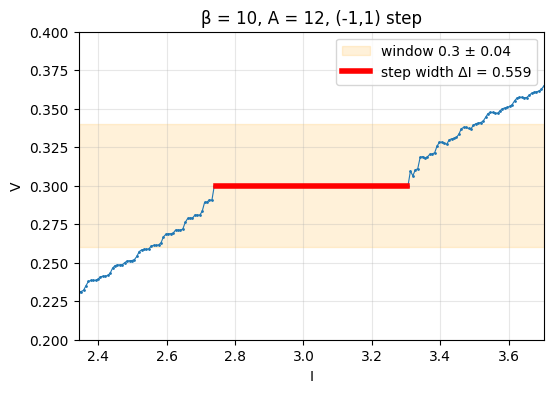

In [8]:
w, (Vmean, I_lo, I_hi) = extract_kyozai(I, Va, 0.3, 0.02, 0.04, return_group=True)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(I, Va, ".-", ms=2, lw=0.8)
ax.axhspan(0.3 - 0.04, 0.3 + 0.04, color="orange", alpha=0.15, label="window 0.3 ± 0.04")
ax.plot([I_lo, I_hi], [Vmean, Vmean], "r", lw=4, label=f"step width ΔI = {w:.3f}")
ax.set_xlim(I_lo - 0.4, I_hi + 0.4); ax.set_ylim(0.2, 0.4)
ax.set_xlabel("I"); ax.set_ylabel("V"); ax.legend(); ax.grid(alpha=.3)
ax.set_title(f"β = 10, A = {A[a]:.0f}, (-1,1) step")
plt.show()

## 7.6 すべての A でステップ幅を求める

リスト内包表記で、33本の IV 曲線すべてから幅を取り出します。

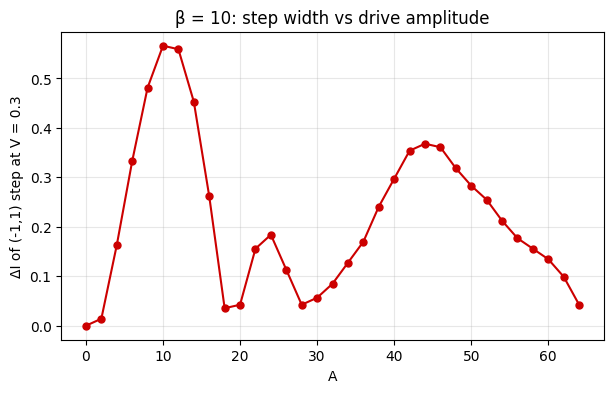

[0.    0.014 0.163 0.333 0.481 0.566 0.559 0.453 0.262 0.035 0.042 0.156
 0.184 0.113 0.042 0.057 0.085 0.127 0.17  0.241 0.297 0.354 0.368 0.361
 0.319 0.283 0.255 0.212 0.177 0.156 0.134 0.099 0.042]


In [9]:
sw = np.array([extract_kyozai(I, V[:, j], 0.3, 0.02, 0.04) for j in range(A.size)])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(A, sw, "o-", c="#cc0000", ms=5)
ax.set_xlabel("A"); ax.set_ylabel("ΔI of (-1,1) step at V = 0.3")
ax.set_title("β = 10: step width vs drive amplitude"); ax.grid(alpha=.3)
plt.show()
print(np.round(sw, 3))

ステップ幅は A とともに増えたり減ったりして、いくつかの山（**ローブ**）を作ります。A ≈ 18〜20 と A ≈ 28 で小さくなり（谷）、その間と後ろに2つ目・3つ目の山が出ています。

研究の報告書が問題にしていたのは、**この3つ目の山（第3ローブ）が、ベッセル関数1つの理論で予想されるより高い**ことでした。次の章でその理論曲線を作って、比べてみます。

## 7.7 しきい値を変えるとどうなるか

測り方の「さじ加減」で答えが変わらないかを確かめるのも大切です。thr を変えてみます。

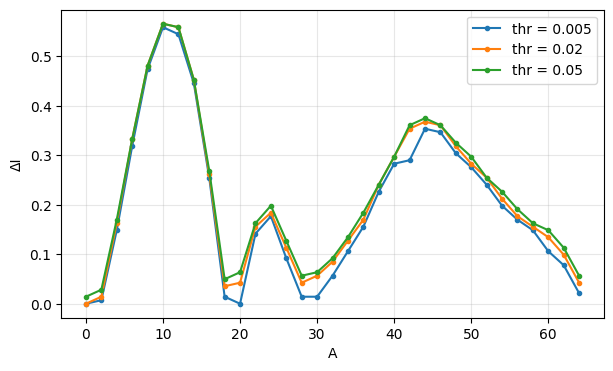

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for thr in [0.005, 0.02, 0.05]:
    s = [extract_kyozai(I, V[:, j], 0.3, thr, 0.04) for j in range(A.size)]
    ax.plot(A, s, "o-", ms=3, label=f"thr = {thr}")
ax.set_xlabel("A"); ax.set_ylabel("ΔI"); ax.legend(); ax.grid(alpha=.3)
plt.show()

しきい値を変えると幅の値は少し変わりますが、山の形は大きくは変わらないことが図から読み取れます。研究では thr = 0.02 を使い、MATLAB の保存値 `sw_all` と差 0 になることを確かめています（研究リポジトリ `lab/式と前提.md` 4章）。この教材では保存値との照合はしていません。

MATLAB の別のスクリプト `step_width_from_iv.m`（`matlab/60_発表/R8_oubutsu/oubutu_sub_0906/`）は、傾きを使わず「電圧の窓」だけで段を選び、両端を**線形補間**で格子より細かく決める、別の測り方です。測り方が違えば値も少し違うので、比べるときは同じ方法にそろえます。

## 第7章の MATLAB ↔ Python 対応

| やりたいこと | MATLAB | Python |
|---|---|---|
| 隣どうしの差 | `diff(V)` | `np.diff(V)`（同じ） |
| 条件に合う番号 | `find(on)`（1 始まり） | `np.where(on)[0]`（0 始まり） |
| 有限の数か | `isfinite(d)` | `np.isfinite(d)` |
| 「でない」 | `~on` | `~on`（同じ。ただし数1つなら `not`） |
| 「かつ」 | `a & b` | `(a) & (b)`（かっこが要る） |
| 1つでも True か | `any(on)` | `on.any()` |
| 警告を止める | `warning('off', ...)` | `with np.errstate(divide="ignore"):` の中だけ止まる |
| 塊に分ける | （決まった関数はなく、`find(diff(idx) > 1)` で切る） | `np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)` |

全章の分をまとめたものは [`対応表.md`](../対応表.md) にあります。

## 穴埋め練習

7.2 の「中点」と「傾き」を、5点の作り物で計算します。

In [11]:
# 穴埋め：___ を埋めてから、全部の行を選んで Cmd + /（Windows は Ctrl + /）を押し、行頭の # を外して実行する
# I_t = np.array([0.0, 0.1, 0.2, 0.3, 0.4])
# V_t = np.array([0.1, 0.3, 0.3, 0.3, 0.5])
# Im_t = (I_t[1:] + I_t[___]) / 2
# slope_t = np.abs(np.diff(V_t) / np.___(I_t))
# print(Im_t, slope_t)

<details><summary>穴埋めの答え（クリックで開く）</summary>

1つ目は `:-1`（最後の1つを除いた全部）、2つ目は `diff` です。中点は [0.05, 0.15, 0.25, 0.35]、傾きは [2, 0, 0, 2] になります。
</details>

下のセルは答えを埋めた版です。自分で埋めた結果と同じになるか確かめてください。

In [12]:
# 答え合わせ（埋めた版）
I_t = np.array([0.0, 0.1, 0.2, 0.3, 0.4])
V_t = np.array([0.1, 0.3, 0.3, 0.3, 0.5])
Im_t = (I_t[1:] + I_t[:-1]) / 2
slope_t = np.abs(np.diff(V_t) / np.diff(I_t))
print(Im_t, slope_t)

[0.05 0.15 0.25 0.35] [2. 0. 0. 2.]


## 予想してから実行

**問題：** 上の作り物の IV 曲線では、V = 0.3 の点が I = 0.1, 0.2, 0.3 の3つ並んでいます。7.4 の `extract` でステップ幅を測ると（Vt = 0.3、thr = 0.02、sr = 0.04）、答えは **0.2** でしょうか、**0.1** でしょうか、それとも別の値でしょうか。

**先に予想を紙かメモに書いてから**、次のセルを実行してください。

In [13]:
print(extract(I_t, V_t, 0.3, 0.02, 0.04))

0.09999999999999998


<details><summary>解説（実行してから開く）</summary>

答えは **約 0.1** です（小数の誤差で 0.09999… と出ることがあります）。

`extract` は点そのものではなく**中点**で測ります。平らな区間は「0.1〜0.2 の間」と「0.2〜0.3 の間」の2つで、その中点は 0.15 と 0.25 です。幅は 0.25 − 0.15 = 0.1 になります。点で数えた 0.3 − 0.1 = 0.2 より、刻み1つ分短くなります。

研究の保存データ（β = 10）では電流の刻みが 0.0070779 なので、この差はステップ幅にくらべて小さいですが、**測り方の定義**として知っておくと、別の方法（7.7 の `step_width_from_iv.m`）の値と比べるときに役立ちます。
</details>

## 練習問題

1. (1, 0) ステップ（V = 0.5）の幅を、窓 ±0.07 で求めてください。この教材の IV マップは I = 1.6〜4.2 しか計算していないので、V = 0.5 の段が範囲に入っているか、まず図で確かめてください。
2. `extract` で「2点未満の塊は捨てる」の行を消すと、結果は変わりますか。どんなときに変わりそうですか。

<details><summary>答え</summary>

1. I = 1.6〜4.2 では V はおよそ 0.13〜0.43 までしか届かない（下のセルの出力）ので、V = 0.5 の段は範囲の外です。`extract` は 0 を返します。研究の保存データは電流をもっと広くとっています。
2. `len(g) < 2` の塊は中点が1つだけなので、幅 `Im[g[-1]] - Im[g[0]]` は 0 になります。消しても最大値は変わりません（全部が1点の塊なら 0 のまま）。この行は「1点だけの偶然の平らさを段とみなさない」という意味をはっきりさせるためのものです。
</details>

In [14]:
print("V の範囲:", V.min(), "〜", V.max())
print("(1,0) の幅:", [round(extract_kyozai(I, V[:, j], 0.5, 0.02, 0.07), 3) for j in range(0, 33, 8)])

V の範囲: 0.12665526323375492 〜 0.4283350160479974
(1,0) の幅: [0.0, 0.0, 0.0, 0.0, 0.0]


## まとめ
- ステップ幅 = 「電圧の窓の中」かつ「傾きがしきい値より小さい」点の、とぎれずに続く一番長い区間の電流の幅。
- `np.diff`・ブールマスク・`np.where`・`np.split` の組み合わせで、`for` を最小限にして書ける。
- 数を出したら、図に重ねて確かめる。測り方（しきい値・補間）で値は少し変わる。